## MERFISH downstream analysis overview

In this section, we demonstrate downstream analysis for the MERFISH dataset (after applying the Heartnet annd getting the annotaions).

1. **Patch-level embedding (UMAP)**
   - We first compute a patch-level representation and visualize patches in a **UMAP** space.
   - This helps us inspect how patches organize into distinct **clusters / patch groups**.

2. **Inspecting representative patches**
   - To make the clusters more interpretable, we select **random patches** from each cluster and display them in a grid/matrix.
   - This allows us to compare the **spatial patterns** and the “real” appearance of patches across different patch groups.

3. **Sample-level analysis with PILOT**
   - Next, we use **PILOT** for sample-level analysis.
   - We visualize the **trajectory of samples** and relate each sample to its **corresponding tissue**.
   - Samples/tissues are colored by their **dominant patch cluster composition**, making it easier to connect patch-level structure to higher-level biological organization.

📌 **PILOT**  
PILOT documentation: https://pilot.readthedocs.io/en/latest/


In [49]:
import os
desired_path = '/data/mu0611151/data/mask/Paul/Github/HeartNet/analysis' 
os.chdir(desired_path)

In [50]:
from pilotpy.tools import *
from pilotpy.plot import *
current_dir = os.getcwd()
src_path = os.path.abspath(os.path.join(current_dir, '..', 'src'))

if src_path not in sys.path:
    sys.path.append(src_path)
from heartnet.visualization import plot_umap_with_patches

In [27]:
merfish=sc.read_h5ad('/data/scRNA/To_Mehdi/pan_data/his_seems_last_version/Merfish_v0.h5ad')
merfish.obs["Sample_IDs"] = merfish.obs["match_id"].str.extract(r"(^.*?\.ome)")
merfish=merfish[~merfish.obs['Sample_IDs'].isin(['T20-07103-I-1_region_1.ome', 'T20-07103-I-1_region_2.ome', 'T21-09706_region_0.ome'])].copy() 

In [28]:
merfish.obs['diagnosis_CK'].unique()

['control', 'ICM', 'ICM_AMI']
Categories (3, object): ['ICM', 'ICM_AMI', 'control']

In [30]:
wasserstein_distance(merfish,emb_matrix='X_pca_harmony',
clusters_col='patch_annotation',sample_col='Sample_IDs',status='diagnosis_CK',metric='euclidean')

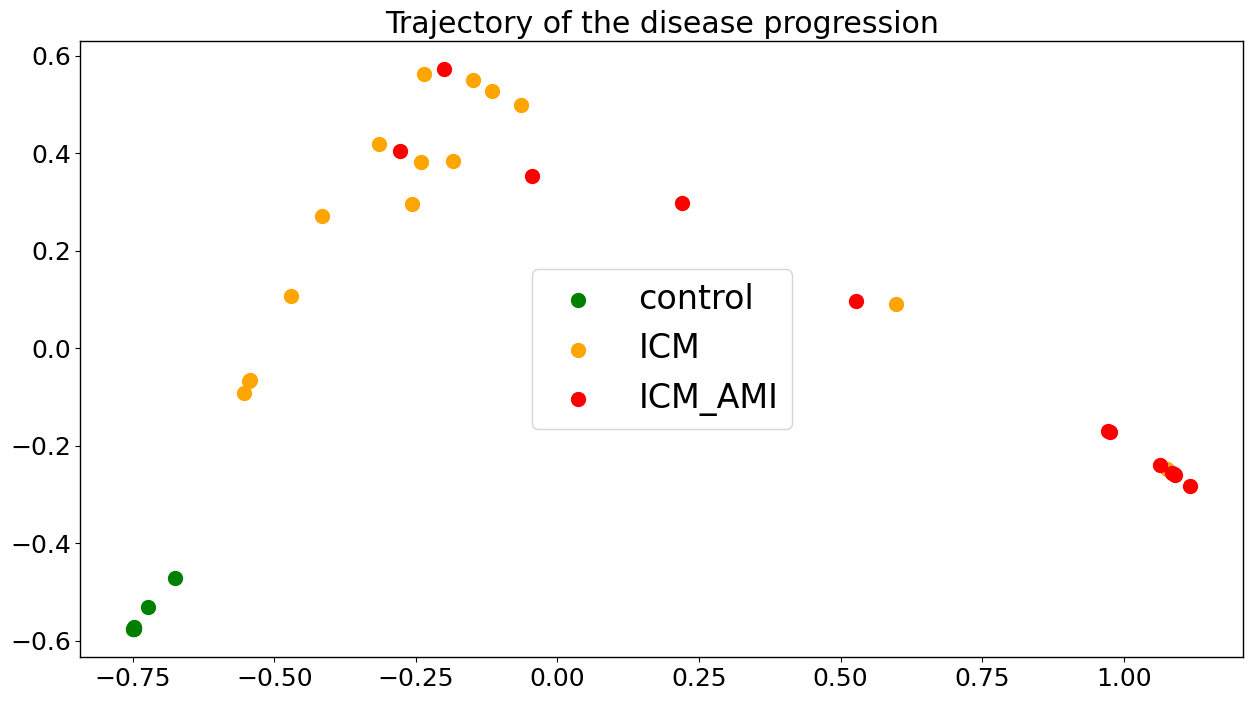

In [13]:
trajectory(merfish,colors=['green','orange','red','blue'],label_act=False,font_size=18,knn=10,figsize=(15,8))

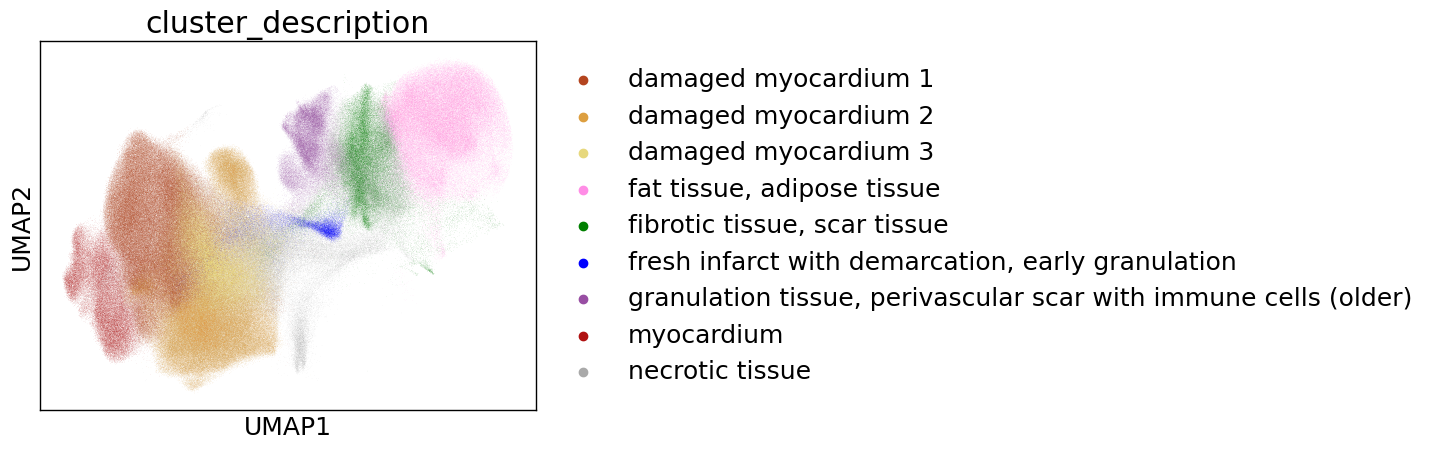

In [14]:
merfish.obs['cluster_description'] = merfish.obs['patch_annotation'].astype(str)
merfish.obs['cluster_description'] = merfish.obs['cluster_description'].astype('category')

class_to_color = {
     "damaged myocardium 1": "#b4451f",
    "damaged myocardium 2": "#dd9f40",
    "fat tissue, adipose tissue": "#FF8DE6",
    "damaged myocardium 3": "#e7d87d",
    "fibrotic tissue, scar tissue": "green",
    "necrotic tissue": "#A9A9A9",
    "myocardium": "#b01111",
    "granulation tissue, perivascular scar with immune cells (older)": "#984ea3",
    "fresh infarct with demarcation, early granulation": "blue",
}


leiden_labels = list(merfish.obs['cluster_description'].cat.categories)
merfish.uns['cluster_description_colors'] = [class_to_color[label] for label in leiden_labels]
sc.pl.umap(merfish, color=['cluster_description'])

In [34]:
merfish

AnnData object with n_obs × n_vars = 1014647 × 1536
    obs: 'X', 'Y', 'Sample_ID', 'Patch_ID', 'match_id', 'diagnosis_CK', 'Batch', 'leiden', 'leiden_03', 'leiden_04', 'leiden_05', 'patch_annotation', 'Sample_IDs'
    uns: 'leiden', 'neighbors', 'umap', 'data', 'annot', 'proportions', 'cost', 'EMD_df', 'EMD', 'real_labels'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    obsp: 'connectivities', 'distances'

Overlaying patches from: /data/scRNA/To_Mehdi/pan_data/spatial/his_merfish/Patches


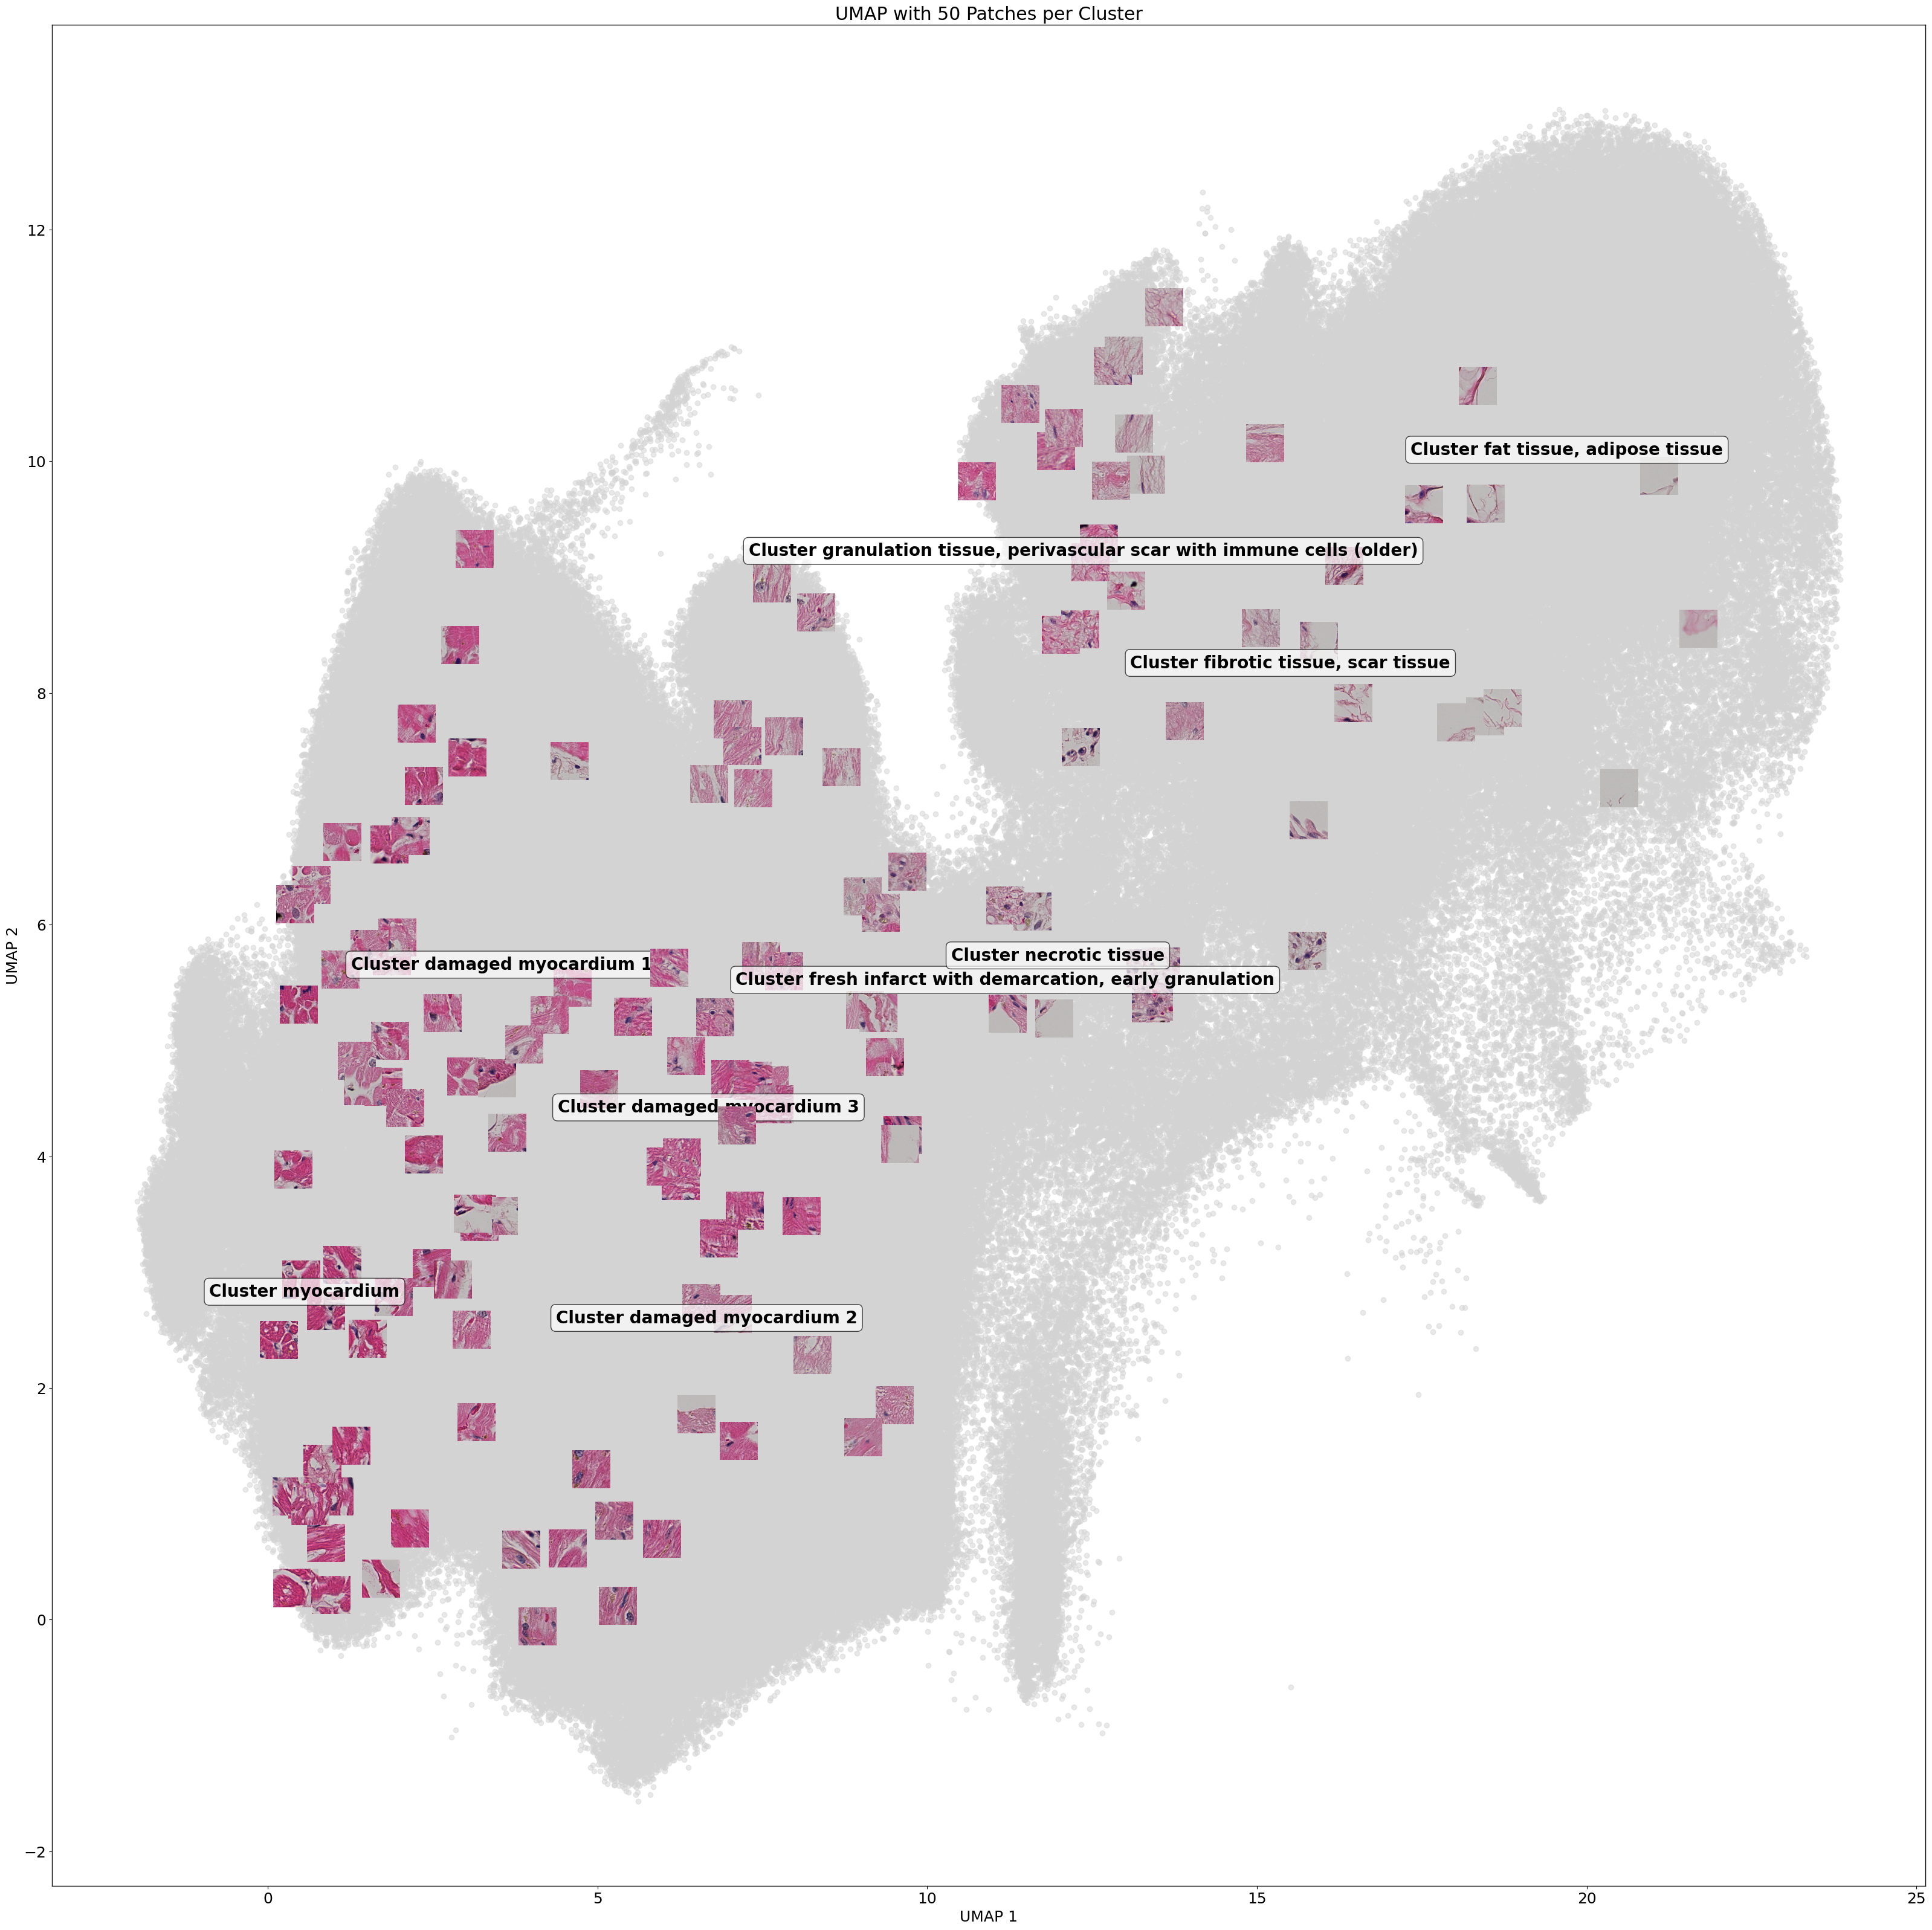

In [55]:
PATCH_FOLDER = "/data/scRNA/To_Mehdi/pan_data/spatial/his_merfish/Patches"

fig = plot_umap_with_patches(
    merfish, 
     slide_col="Sample_IDs", 
      patch_col="Patch_ID", 
     cluster_col="patch_annotation", 
    patch_base_folder=PATCH_FOLDER,
    zoom=0.2,      
    n_patches=50 ,
    figsize=(40, 40)
)

plt.show()
#fig.savefig('umap_patches.pdf')

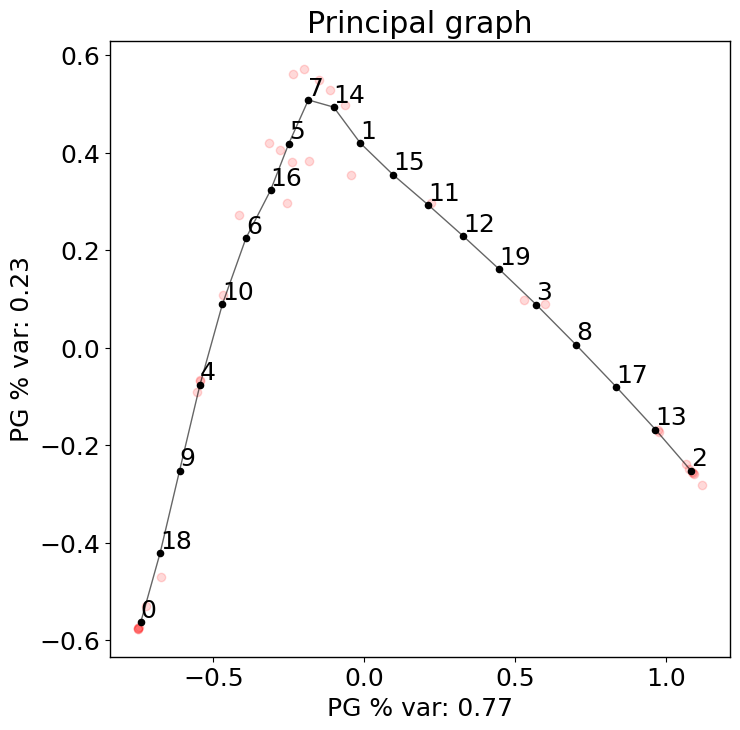

In [18]:
fit_pricipla_graph(merfish, source_node =0,figsize=(8,8))

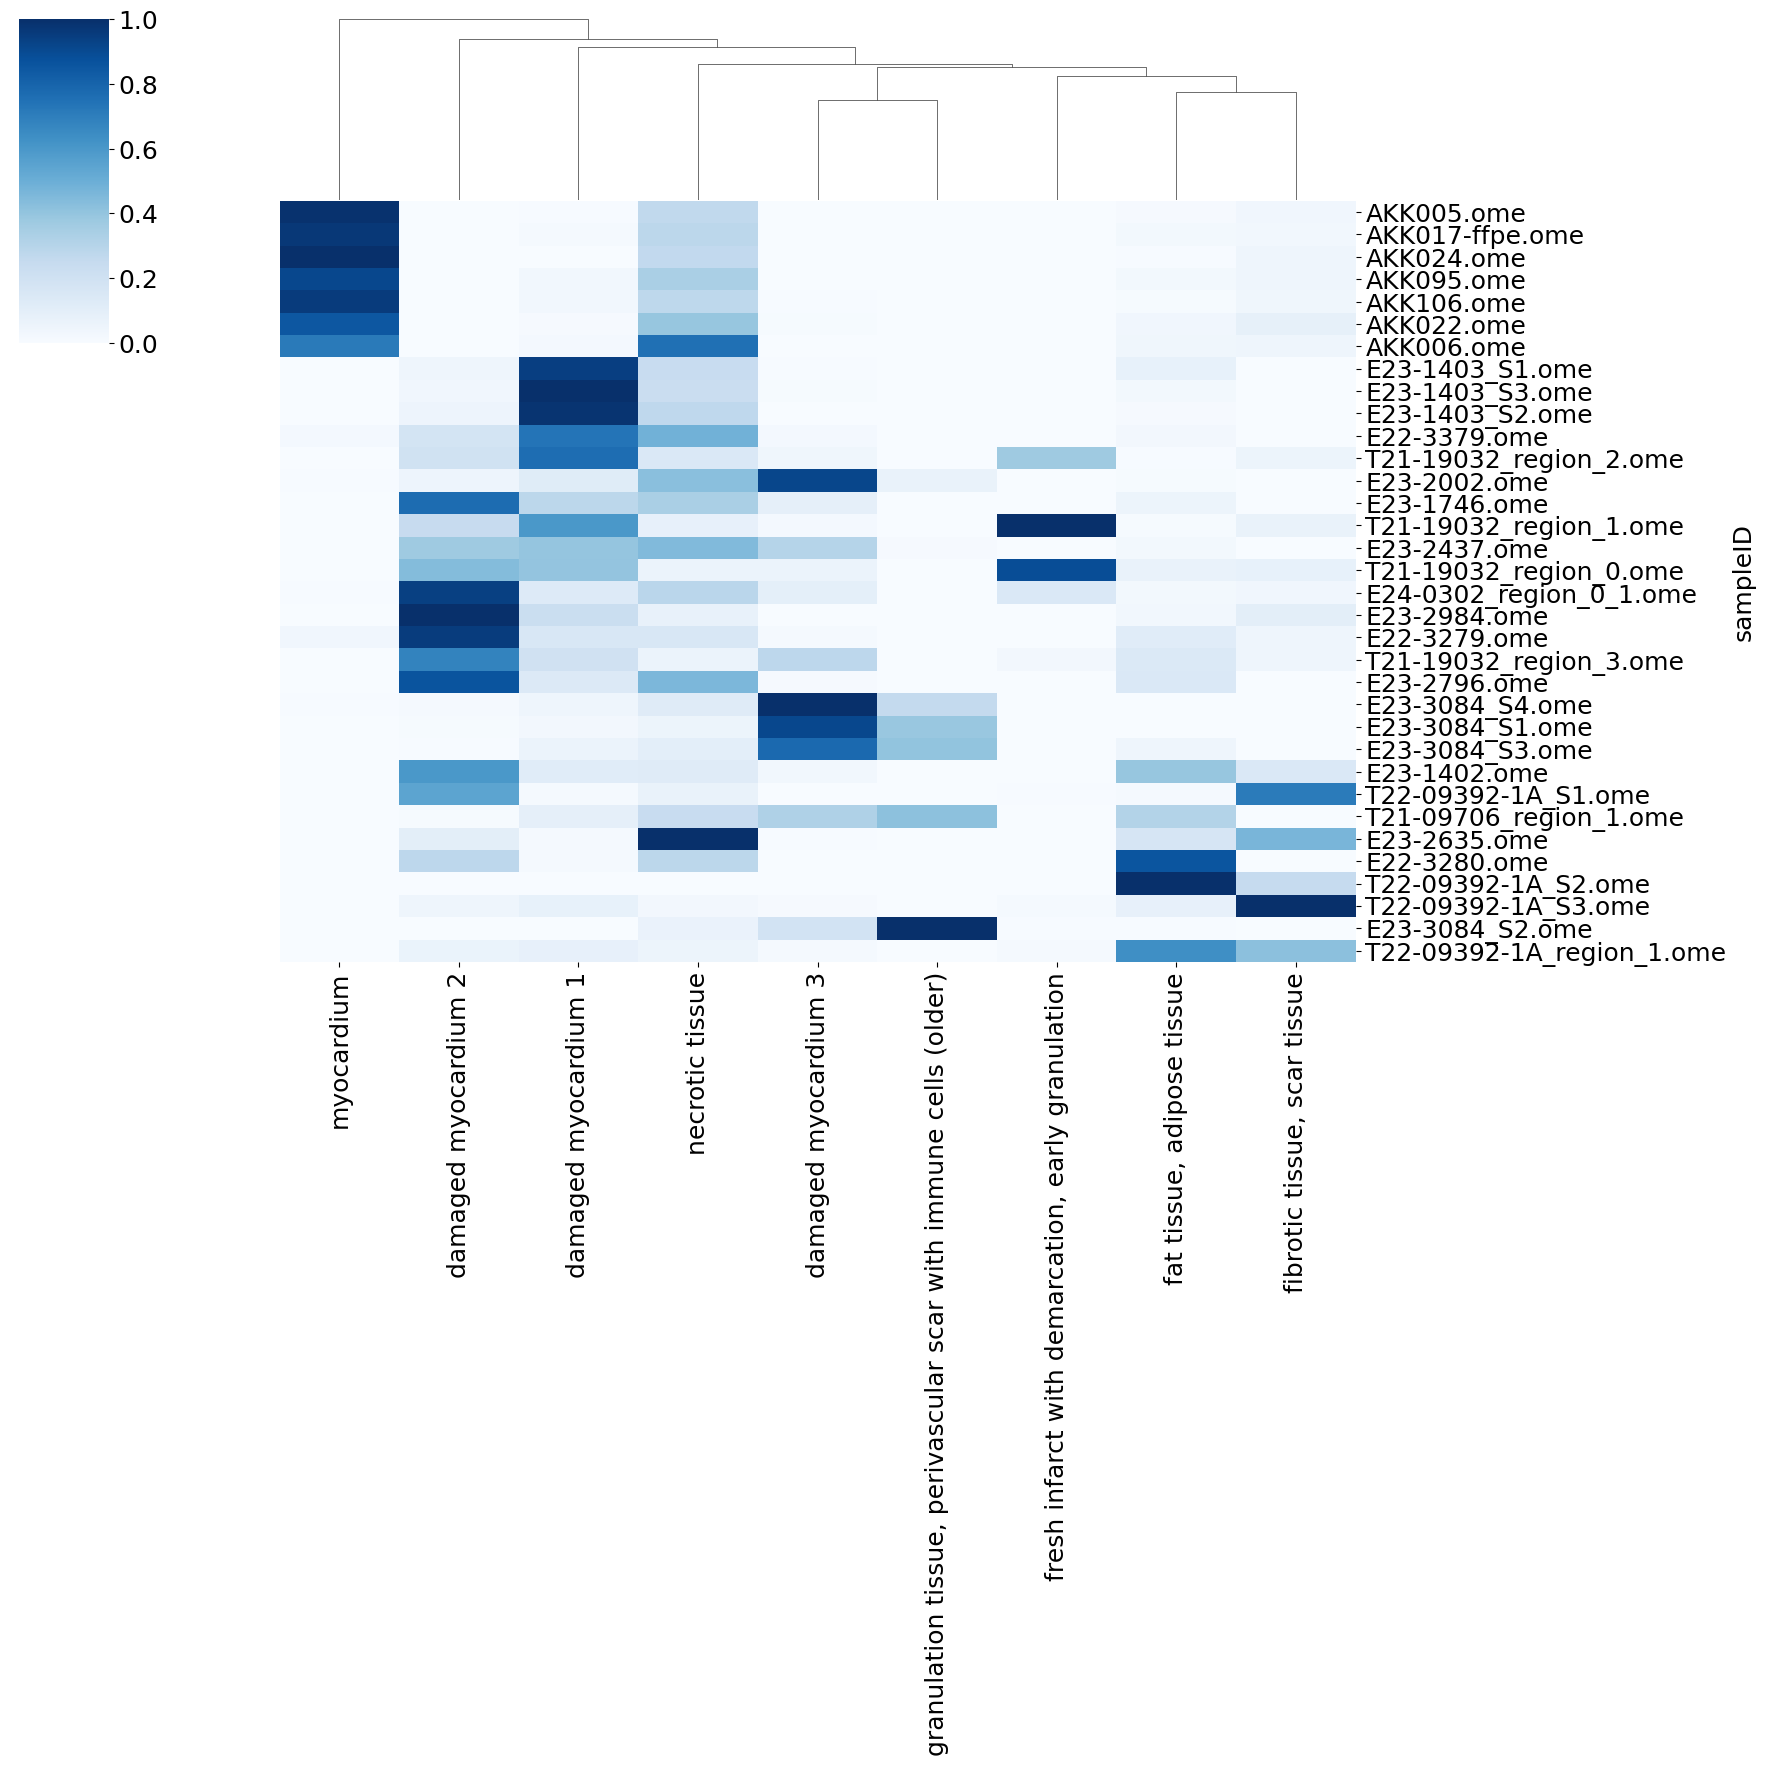

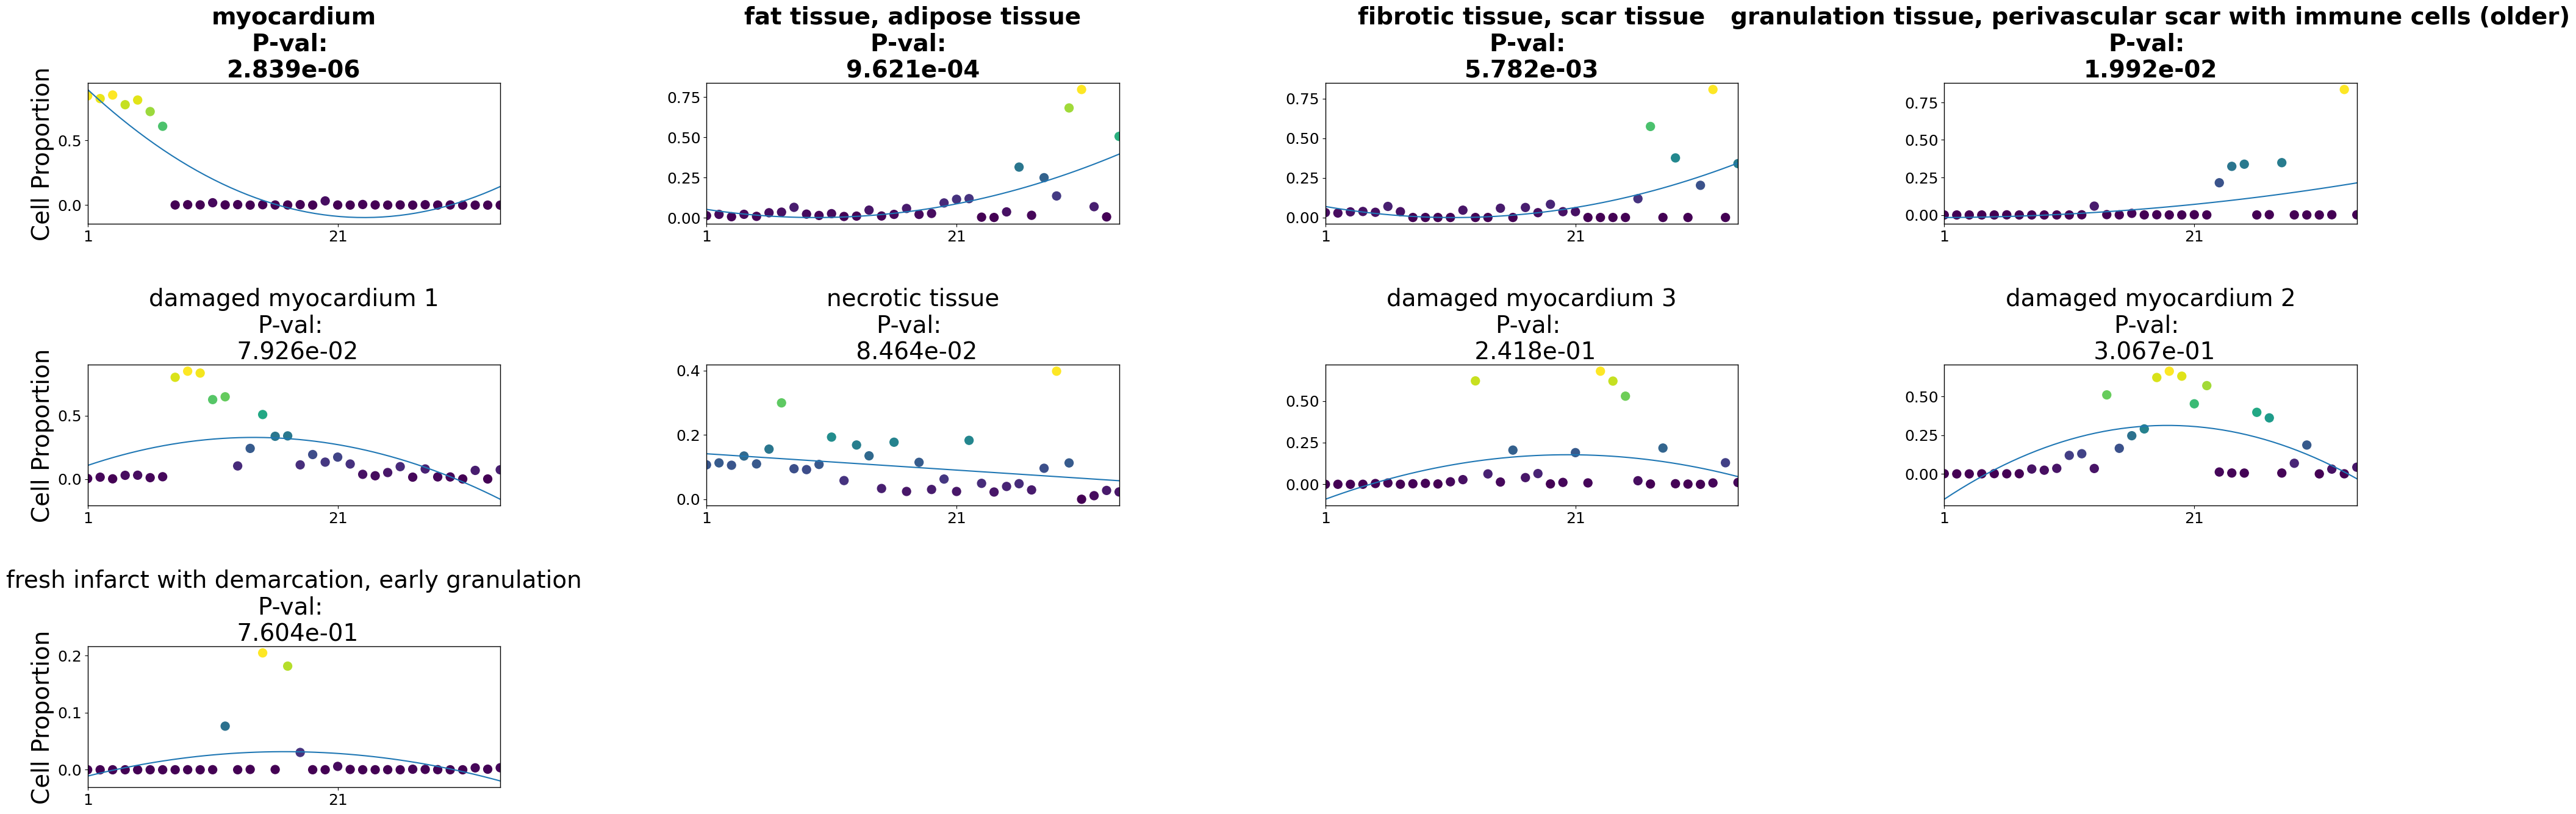

In [21]:

cell_importance(merfish,height=15,width=48,fontsize=28,xlim=20,figsize=(18,18))

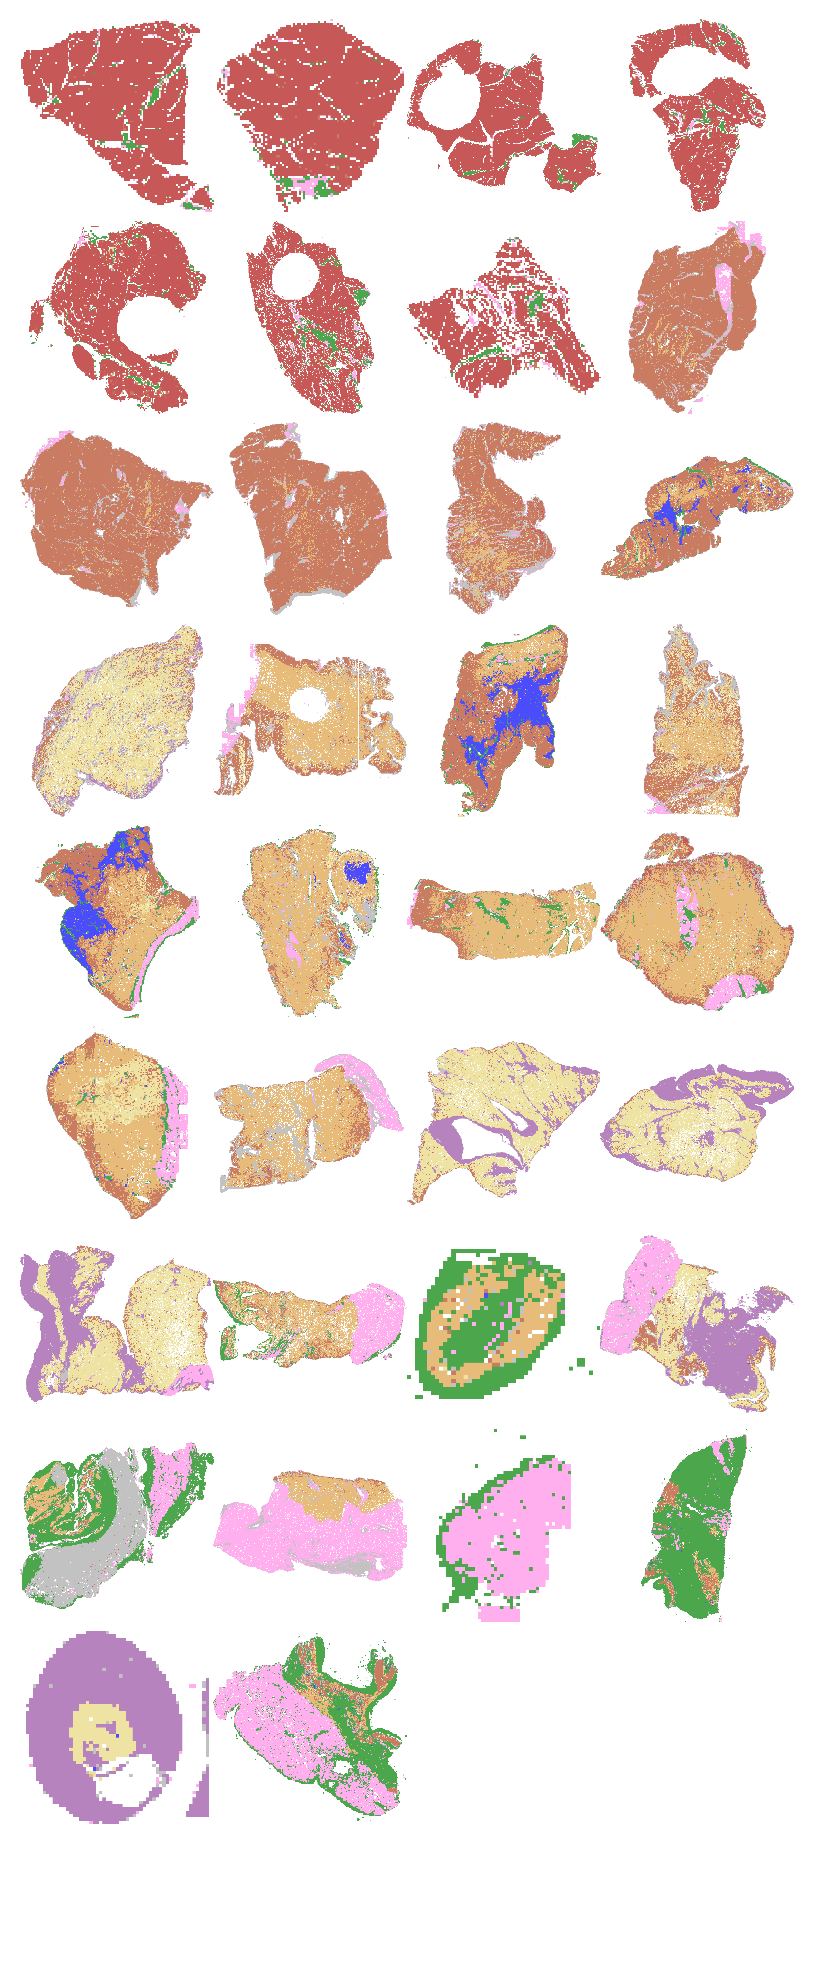

Saved grid with 34 images to Results_PILOT/Cores_based_his_only.pdf


In [23]:
merfish.uns['orders'].rename(columns={'Time_score': 'pseudotime'}, inplace=True)
create_sample_grid(df=merfish.uns['orders'],image_dir='/data/scRNA/To_Mehdi/pan_data/spatial/colored_patches_clusters_with_xenium_clusters_cleaning_annotations/', output_path="Results_PILOT/Cores_based_his_only.pdf")